In [5]:
# Ejecutar programas externos
import subprocess  
'''
Count interables like lists, 
It could be used this way: Counter to investigate how frequently 
different Agencia_ID values appear in a sample
'''
from collections import Counter
from pathlib import Path
import cv2 as cv
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np

In [6]:
#plt.rcParams["figure.dpi"] = 80 ( Imagenes demasiado pesadas, NUNCA usar esto)
np.random.seed(42)
#No poner el caracter '/' aqui, ya que ira a la raiz de C:\
DATOS = Path("../data/raw") #usar r"path" si es que necesitas poner el path completo, aqui no pero

print("Dataset Listo en: ", DATOS.resolve())
print("OpenCV:", cv.__version__, "| Numpy:", np.__version__ )

Dataset Listo en:  C:\Users\alexi\Desktop\Personal\Proyecto_CV\Project_Active\data\raw
OpenCV: 4.11.0 | Numpy: 1.26.4


Ref C:\Users\alexi\Desktop\Personal\Proyecto_CV\Project_Active\data\raw\producto_antoni\antoni1.jpg


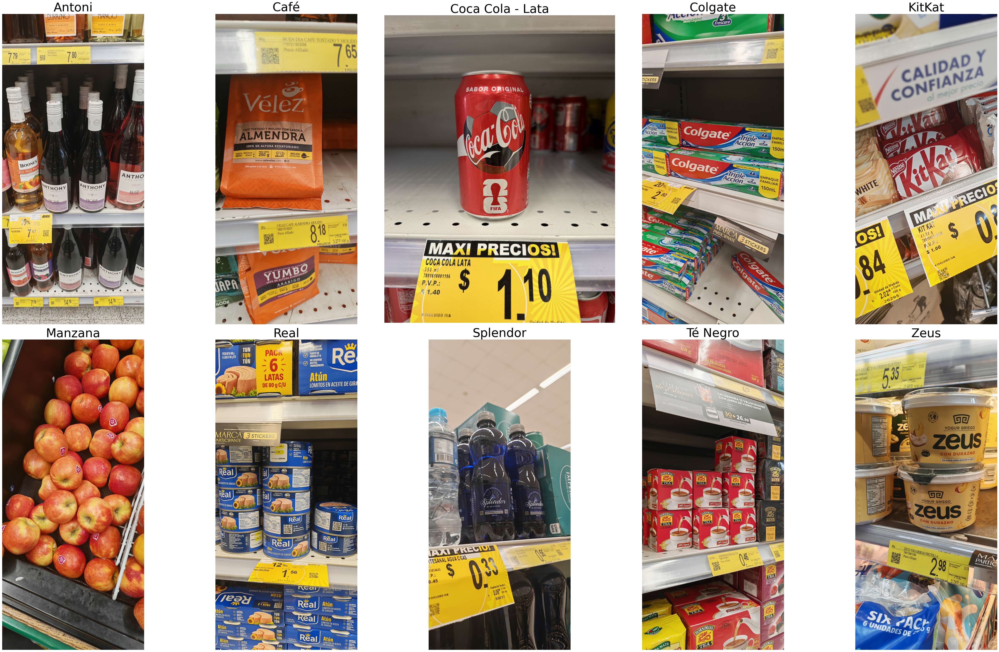

In [7]:
#algo importante aqui es:
#cuando se carga una imagen con cv.imread() se devuelve un np.ndarray
#numpy array, entonces esto es lo que estas viendo dentro del metodo
#mostrar, atributos como .dtype y .ndim pertenece un array numpy.
#ndim: Numero de dimensiones | dtype: np.uint8 o np.float32, etc | 

def leer_rgb(ruta):
    #leer en RGB
    return cv.cvtColor(cv.imread(str(ruta)), cv.COLOR_BGR2RGB)

def mostrar(imagenes, titulos, cmap=None, ancho=10):
    #(rows, columns, width and height of the figure)
    #
    fig, axes = plt.subplots(2,5, figsize=(ancho*5, ancho*3))
    for ax, im, tit in zip(np.atleast_1d(axes).ravel(),imagenes, titulos): #no se porque usa np.atleast_1d pero no es necesario en otro codigo que hice antes
        if im.ndim == 2: # si es que tiene 2 dimensiones, recuerda canal en gris tiene 2 canales
            fijo = im.dtype == np.uint8 #Asignacion de variable en base a comparacion '=='
            #Aqui el primer cmap es el argumento del metodo de abajo, 
            #el segundo ES EL PARAMETRO QUE SE LE PASA A ESTE METODO QUEEEEEEE
            ax.imshow(im, cmap=cmap or "gray", vmin = 0 if fijo else None, vmax= 255 if fijo else None)
            #Que metodo mas raro xd
        else:
            ax.imshow(im)
        ax.set_title(tit, fontsize = 40)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

        
TRAIN = DATOS # por ahora todas las imagenes son de train
#Vamos con los 10 productos
print("Ref", (TRAIN / "producto_antoni/antoni1.jpg").resolve())

ANTONI = leer_rgb(TRAIN / "producto_antoni/antoni1.jpg")
CAFE = leer_rgb(TRAIN / "producto_cafe/cafe1.jpg")
COCACOLA = leer_rgb(TRAIN / "producto_cocacola/cocacola1.jpg") #Este es el unico que tiene mas de carpeta dentro de otra
COLGATE = leer_rgb(TRAIN / "producto_colgate/colgate1.jpg")
KITKAT = leer_rgb(TRAIN / "producto_kitkat/kitkat1.jpg")
MANZANA = leer_rgb(TRAIN / "producto_manzana/manzana1.jpg")
REAL = leer_rgb(TRAIN / "producto_real/real1.jpg")
SPLENDOR = leer_rgb(TRAIN / "producto_splendor/splendor1.jpg")
TENEGRO = leer_rgb(TRAIN / "producto_tenegro/tenegro1.jpg")
ZEUS = leer_rgb(TRAIN / "producto_zeus/zeus1.jpg")

mostrar(
    [ANTONI, CAFE, COCACOLA, COLGATE, KITKAT, MANZANA, REAL, SPLENDOR, TENEGRO, ZEUS],
    ["Antoni", "Café", "Coca Cola - Lata", "Colgate", "KitKat", "Manzana", "Real", "Splendor", "Té Negro", "Zeus"]
)

In [9]:
#vision clasica: Reglas y geometria --> Machine learning: con caracteristicas hechas a mano --> Deep learning: CNN que aprende 
#sus propias caracteristicas --> Transformers y modelos multimodales
''' Muy bien entonces ahora vamos distribucion de clases''' 
#Funny enough, when you spend time on something, you actually learn, who would have thought
RAIZ = Path("../data/raw")
FORMATOS_FOTOS = ['.jpg']#Por ahora solo se usaran .jpg (transformar otras fotos a este formato)

lista = [] 
for carpeta in sorted(RAIZ.iterdir()):
    if not carpeta.is_dir():
        continue
    for img in sorted(carpeta.iterdir()):
        if img.suffix.lower() in FORMATOS_FOTOS:
            #print(img)
            lista.append({"clase": carpeta.name, "ruta": str(img)})

df = pd.DataFrame(lista) 
df["clase_id"] = df["clase"].astype("category").cat.codes 
'''
Path atributos: 
img.name       # 'imagen.JPG'
img.stem       # 'imagen'
img.suffix     # '.JPG'
img.parent     # 'mis_fotos/cocacola'
img.suffixes   # ['.JPG']
'''
#accesor de pandas

"\nPath atributos: \nimg.name       # 'imagen.JPG'\nimg.stem       # 'imagen'\nimg.suffix     # '.JPG'\nimg.parent     # 'mis_fotos/cocacola'\nimg.suffixes   # ['.JPG']\n"

In [10]:
df.head()

,clase,ruta,clase_id
0,producto_antoni,..\data\raw\producto_antoni\antoni1.jpg,0
1,producto_antoni,..\data\raw\producto_antoni\antoni10.jpg,0
2,producto_antoni,..\data\raw\producto_antoni\antoni11.jpg,0
3,producto_antoni,..\data\raw\producto_antoni\antoni12.jpg,0
4,producto_antoni,..\data\raw\producto_antoni\antoni13.jpg,0


In [11]:
from sklearn.model_selection import train_test_split 

train, test = train_test_split(df, test_size= 0.2, stratify=df['clase'], random_state=42) 

#Aqui usar .assign() en vez de usar cosas como train['split'] = 'train', se usa
#Ya que assign retorna un nuevo datagrame en vez de cambiar el original 
df = pd.concat([train.assign(split='train'),test.assign(split='test') ],ignore_index=True)

In [12]:
df.head()

,clase,ruta,clase_id,split
0,producto_tenegro,..\data\raw\producto_tenegro\tenegro59.jpg,8,train
1,producto_zeus,..\data\raw\producto_zeus\zeus46.jpg,9,train
2,producto_cafe,..\data\raw\producto_cafe\cafe38.jpg,1,train
3,producto_colgate,..\data\raw\producto_colgate\colgate36.jpg,3,train
4,producto_splendor,..\data\raw\producto_splendor\splendor32.jpg,7,train


clase
producto_cocacola     8
producto_kitkat      20
producto_manzana     33
producto_cafe        47
producto_real        52
producto_splendor    64
producto_zeus        68
producto_colgate     72
producto_tenegro     92
producto_antoni      94
Name: count, dtype: int64


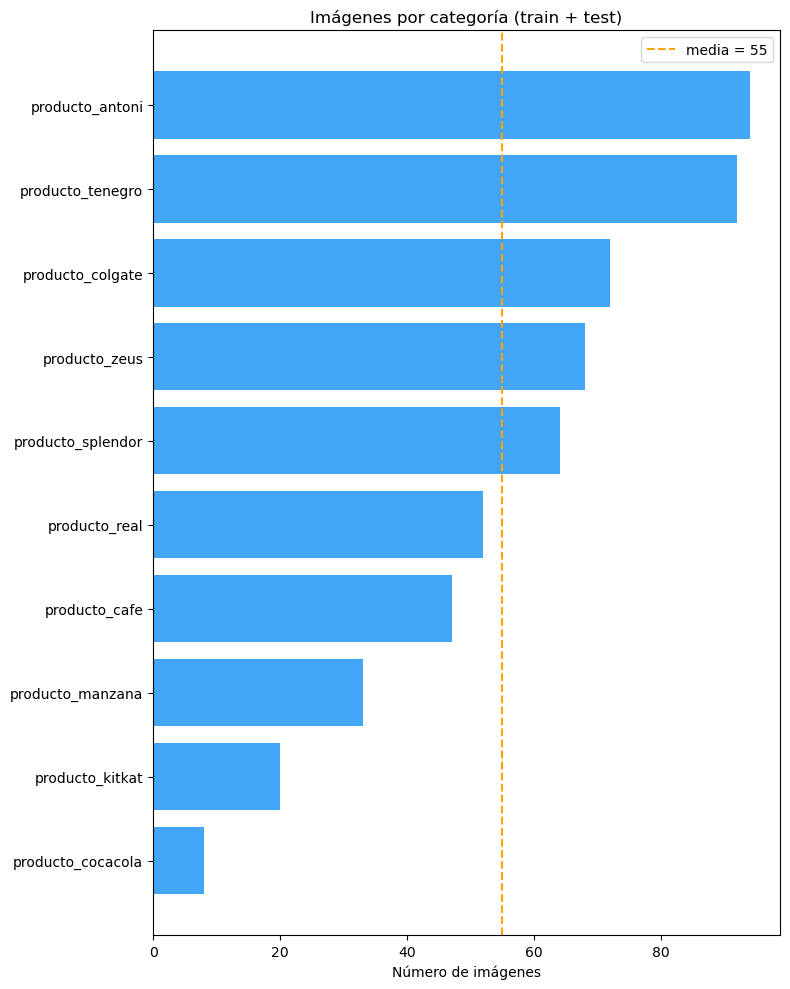

Mínimo: 8 (producto_cocacola)  |  Máximo: 94 (producto_antoni)
Razón de desbalance máx/mín: 11.8x


In [13]:
conteo = df["clase"].value_counts().sort_values()
print(conteo)
plt.figure(figsize=(8, 10))
plt.barh(conteo.index, conteo.values, color="#42A5F5")
plt.axvline(conteo.mean(), color="orange", ls="--", label=f"media = {conteo.mean():.0f}")
plt.title("Imágenes por categoría (train + test)")
plt.xlabel("Número de imágenes")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Mínimo: {conteo.min()} ({conteo.idxmin()})  |  Máximo: {conteo.max()} ({conteo.idxmax()})")
print(f"Razón de desbalance máx/mín: {conteo.max() / conteo.min():.1f}x")

In [ ]:
#New line...............

'''
TEST
'''